# Данные

**Dataset:** LiveLib / "По страницам"

**Source:** https://ods.ai/competitions/nto25-26-hack/dataset, для начала работы необходимо создать в корне проекта директорию data, скачать zip-файл с датасетом и перенести его в data.

Датасет содержит обезличенную историю взаимодействий пользователей с книгами и метаданные книг, изданий и пользователей.

### interactions.csv:
Лог событий взаимодействий пользователя с изданиями, каждая строка - одно событие.
- user_id - идентификатор пользователя (FK => users.user_id);
- edition_id - идентификатор издания (FK => editions.edition_id);
- event_type - тип события: 1 - wishlist, 2 - read;
- rating - рейтинг (только для read, иначе NULL);
- event_ts - дата-время события.

### users.csv:
Справочник пользователей с демографическими признаками.
- user_id - идентификатор пользователя (PK);
- gender - пол: 1 - мужской, 2 - женский, NULL - неизвестен;
- age - возраст (может быть NULL).

### editions.csv:
Справочник изданий, каждое издание привязано к одной книге.
- edition_id - идентификатор издания (PK);
- book_id - идентификатор книги;
- author_id - идентификатор автора (FK → authors.author_id);
- publication_year - год публикации	(издания, не книги);
- age_restriction - возрастное ограничение (например, 18+);
- language_id - идентификатор языка (справочник отсутствует);
- publisher_id - идентификатор издателя	(справочник отсутствует);
- title - название;
- description - описание (сравнительно короткое, нестандартизированное).

### authors.csv:
Справочник авторов.
- author_id - идентификатор автора (PK);
- author_name - имя автора (необязательно ФИО, может быть и псевдонимом, и даже несколькими авторами).

### genres.csv:
Справочник жанров.
- genre_id - идентификатор жанра (PK);
- genre_name - название жанра.

### book_genres.csv:
Связь многие-ко-многим между книгами и жанрами, уникальность: (book_id, genre_id).
- book_id - идентификатор книги;
- genre_id - идентификатор жанра (FK → genres.genre_id).

Исходный датасет содержит 231 210 взаимодействий, 5 067 пользователей, 74 528 изданий и 59 026 книг.

In [192]:
import torch
import random
import zipfile
import numpy as np
import polars as pl
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [138]:
SEED = 42
K = 10

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
ARCHIVE_PATH = DATA_DIR / "participants.zip"
SOURCE_DIR = RAW_DIR / "participants" / "data"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [140]:
if not SOURCE_DIR.exists():
    if not ARCHIVE_PATH.exists():
        raise FileNotFoundError
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARCHIVE_PATH, "r") as archive:
        archive.extractall(RAW_DIR)
sorted(p.name for p in SOURCE_DIR.glob("*.csv"))

['authors.csv',
 'book_genres.csv',
 'editions.csv',
 'genres.csv',
 'interactions.csv',
 'users.csv']

In [141]:
interactions = pl.read_csv(
    SOURCE_DIR / "interactions.csv",
    schema_overrides={"event_ts": pl.Datetime},
)
users = pl.read_csv(SOURCE_DIR / "users.csv")
editions = pl.read_csv(SOURCE_DIR / "editions.csv")
authors = pl.read_csv(SOURCE_DIR / "authors.csv")
genres = pl.read_csv(SOURCE_DIR / "genres.csv")
book_genres = pl.read_csv(SOURCE_DIR / "book_genres.csv")

# EDA

In [147]:
# таблицы в целом
tables = {
    "interactions": interactions,
    "users": users,
    "editions": editions,
    "authors": authors,
    "genres": genres,
    "book_genres": book_genres,
}
for name, df in tables.items():
    print(f"\n{name}: {df.shape}")
    display(df.head())


interactions: (231210, 5)


user_id,edition_id,event_type,rating,event_ts
i64,i64,i64,f64,datetime[μs]
560,1012411658,2,6.0,2024-12-24 19:02:14
560,1008465904,2,6.0,2025-01-10 19:18:04
560,1001243738,2,10.0,2025-01-25 11:28:11
560,1009492501,2,8.0,2025-01-25 11:28:42
560,1000118974,2,8.0,2025-03-10 18:14:17



users: (5067, 3)


user_id,gender,age
i64,f64,f64
560,2.0,9.0
3410,2.0,39.0
5620,1.0,42.0
5700,2.0,40.0
6120,2.0,32.0



editions: (134231, 9)


...

author_id,author_name
i64,str
1,"""Грегори Бенфорд"""
6,"""Вячеслав Маркин"""
18,"""Эдвард де Боно"""
19,"""Василий Головачёв"""
21,"""Пауло Коэльо"""



genres: (586, 2)


genre_id,genre_name
i64,str
1,"""Бизнес-книги"""
2,"""Банковское-дело"""
3,"""Бухучет-налогообложение-аудит"""
4,"""Государственное-и-муниципально…"
5,"""Делопроизводство"""



book_genres: (168251, 2)


book_id,genre_id
i64,i64
20,433
20,1217
35,141
35,142
35,146


In [156]:
# nunique, в случае изданий - считаем только те, которые встретились в interactions
used_editions = interactions.select("edition_id").unique()
used_books = editions.join(used_editions, on="edition_id", how="semi")
stats = pl.DataFrame({
    "col": ["interactions", "users", "editions", "books"],
    "value": [
        interactions.height,
        interactions["user_id"].n_unique(),
        interactions["edition_id"].n_unique(),
        used_books["book_id"].n_unique(),
    ]
})
stats

col,value
str,i64
"""interactions""",231210
"""users""",5067
"""editions""",74528
"""books""",59026


In [150]:
# общие статистики
interactions.describe()

statistic,user_id,edition_id,event_type,rating,event_ts
str,f64,f64,f64,f64,str
"""count""",231210.0,231210.0,231210.0,125369.0,"""231210"""
"""null_count""",0.0,0.0,0.0,105841.0,"""0"""
"""mean""",5.4696e6,1.0070e9,1.634311,8.286474,"""2025-01-15 22:08:00.221378"""
"""std""",4.0050e6,3.7931e6,0.481624,1.779718,null
"""min""",560.0,1.0000e9,1.0,1.0,"""2024-10-14 18:48:56"""
"""25%""",1.36127e6,1.0030e9,1.0,8.0,"""2024-12-04 22:11:41"""
"""50%""",5.51959e6,1.0079e9,2.0,8.0,"""2025-01-16 14:51:51"""
"""75%""",9.08446e6,1.0100e9,2.0,10.0,"""2025-02-27 16:29:33"""
"""max""",1.195162e7,1.0159e9,2.0,10.0,"""2025-04-12 12:44:23"""


Рейтинг - по десятибалльной шкале, у 105841 взаимодействий отсутствует, смещен вверх (mean = 8.286474).

Пропусков в таймстемпах нет, период оценивания: 14.10.2024 - 12.04.2025.

rating,count
f64,u32
null,105841
1.0,234
2.0,1247
3.0,388
4.0,3454
…,…
6.0,14823
7.0,9233
8.0,35921


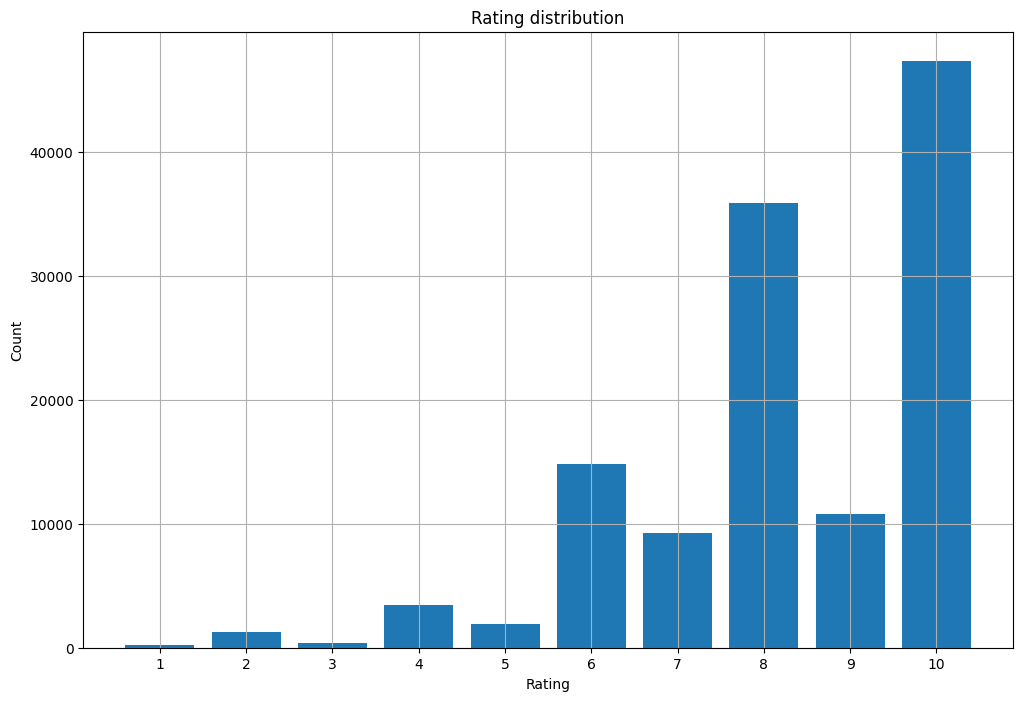

In [162]:
# распределение рейтингов
rating_counts = (
    interactions
    .group_by("rating")
    .len(name="count")
    .sort("rating", nulls_last=False)
)
display(rating_counts)

rated_counts = rating_counts.filter(pl.col("rating").is_not_null())
plt.figure(figsize=(12, 8))
plt.bar(
    rated_counts["rating"].to_numpy(),
    rated_counts["count"].to_numpy(),
)
plt.title("Rating distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rated_counts["rating"].to_numpy())
plt.grid(True)
plt.show()

Помимо очевидной смещенности вверх (человек скорее оценит издание, которое ему понравилось, нежели наоборот + человек скорее прочитает более популярное ~= понравившееся многим издание), интересно, что нечетные рейтинги проигрывают четным.

In [171]:
# статистика по типам взаимодействий:
# 1 - пользователь добавил издание в список желаемого, 2 - пользователь прочитал издание
event_type_stats = (
    interactions
    .group_by("event_type")
    .len(name="count")
    .with_columns((pl.col("count") / pl.col("count").sum()).alias("share"))
    .sort("event_type")
)
event_type_stats

event_type,count,share
i64,u32,f64
1,84551,0.365689
2,146659,0.634311


In [170]:
# покрытие рейтингов по типам событий
rating_by_event = (
    interactions
    .group_by("event_type")
    .agg(
        pl.len().alias("events"),
        pl.col("rating").is_not_null().sum().alias("rated_events"),
        pl.col("rating").is_null().sum().alias("unrated_events"),
        pl.col("rating").is_not_null().mean().alias("rating_coverage"),
    )
    .sort("event_type")
)
rated = interactions.filter(
    pl.col("rating").is_not_null()
    & pl.col("event_ts").is_not_null()
)
rated_coverage = pl.DataFrame({
    "metric": [
        "rated_interactions",
        "rated_users",
        "rated_editions",
        "rated_interactions_share",
        "rated_users_share",
        "rated_editions_share",
    ],
    "value": [
        rated.height,
        rated["user_id"].n_unique(),
        rated["edition_id"].n_unique(),
        rated.height / interactions.height,
        rated["user_id"].n_unique() / interactions["user_id"].n_unique(),
        rated["edition_id"].n_unique() / interactions["edition_id"].n_unique(),
    ],
}, strict=False)
display(rating_by_event)
display(rated_coverage)

event_type,events,rated_events,unrated_events,rating_coverage
i64,u32,u32,u32,f64
1,84551,0,84551,0.0
2,146659,125369,21290,0.854833


metric,value
str,f64
"""rated_interactions""",125369.0
"""rated_users""",4785.0
"""rated_editions""",48995.0
"""rated_interactions_share""",0.54223
"""rated_users_share""",0.944346
"""rated_editions_share""",0.657404


month,count
datetime[μs],u32
2024-10-01 00:00:00,19460
2024-11-01 00:00:00,33896
2024-12-01 00:00:00,36521
2025-01-01 00:00:00,48207
2025-02-01 00:00:00,37414
2025-03-01 00:00:00,40758
2025-04-01 00:00:00,14954


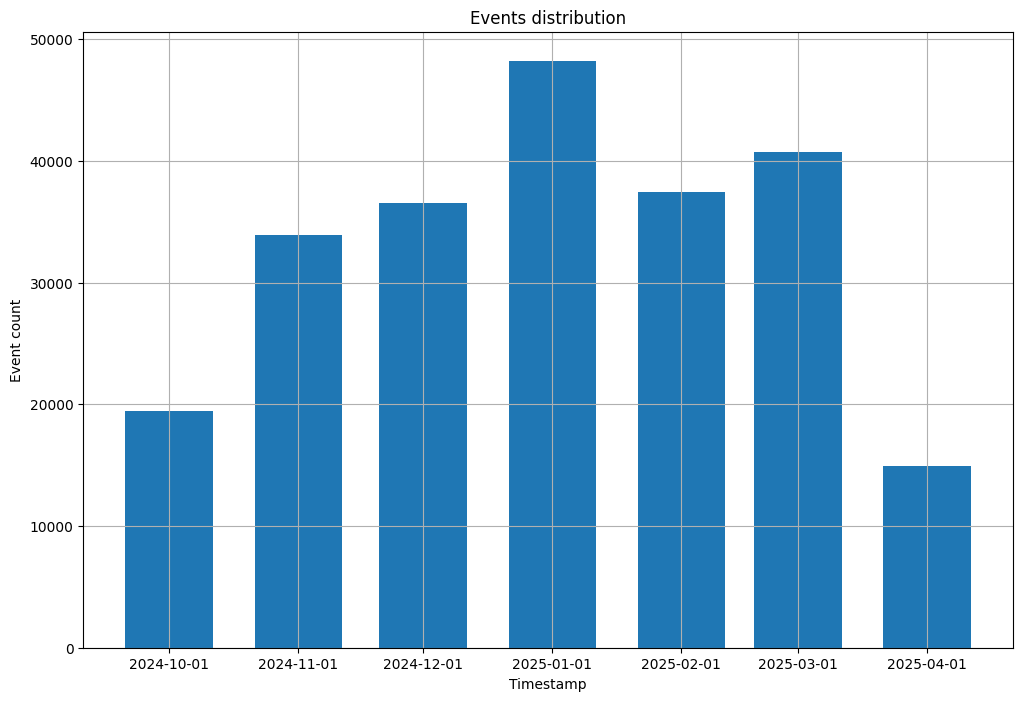

In [193]:
# распределение событий по месяцам
events_counts = (
    interactions
    .with_columns(pl.col("event_ts").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .len(name="count")
    .sort("month", nulls_last=False)
)
display(events_counts)

events_counts = events_counts.filter(pl.col("month").is_not_null())
plt.figure(figsize=(12, 8))
plt.bar(
    events_counts["month"].to_numpy(),
    events_counts["count"].to_numpy(),
    width=pd.Timedelta(weeks=3),
)
plt.title("Events distribution")
plt.xlabel("Timestamp")
plt.ylabel("Event count")
plt.xticks(events_counts["month"].to_numpy())
plt.grid(True)
plt.show()

Тоже неудивительно, что после/на новогодних праздниках люди больше читают (возможно, подаренные им) книги.

In [195]:
# полные дубликаты взаимодействий
duplicates_count = (
    interactions
    .select(pl.struct(pl.all()).is_duplicated().sum())
    .item()
)
# дубликаты взаимодействий пользователь-издание
ui_duplicates_counts = (
    interactions
    .group_by(["user_id", "edition_id"])
    .len(name="n_events")
)
repeated = ui_duplicates_counts.filter(pl.col("n_events") > 1)
duplicates_stats = pl.DataFrame({
    "metric": [
        "duplicates",
        "unique_ui",
        "repeated_ui",
        "users_with_repeated_items",
        "extra_events",
        "max_events_for_ui",
    ],
    "value": [
        duplicates_count,
        ui_duplicates_counts.height,
        repeated.height,
        repeated["user_id"].n_unique(),
        interactions.height - ui_duplicates_counts.height,
        repeated["n_events"].max(),
    ],
})
duplicates_stats

metric,value
str,i64
"""duplicates""",0
"""unique_ui""",231038
"""repeated_ui""",163
"""users_with_repeated_items""",110
"""extra_events""",172
"""max_events_for_ui""",3


Полных дубликатов нет, а повторных пар пользователь-издание мало, но просто их удалять нельзя, т.к. список желаемого -> прочтение одного и того же издания - осмысленная последовательность.

In [203]:
# вся история пар пользователь-издание, у которых есть события обоих типов
repeated_events = (
    interactions
    .filter(
        (pl.col("event_type").is_in([1]).any() & pl.col("event_type").is_in([2]).any())
        .over(["user_id", "edition_id"])
    )
    .sort(["user_id", "edition_id", "event_type", "event_ts"])
)
repeated_events.head(100)

user_id,edition_id,event_type,rating,event_ts
i64,i64,i64,f64,datetime[μs]
216910,1002828837,1,null,2025-03-07 11:43:06
216910,1002828837,2,9.0,2025-03-07 11:43:06
1141490,1006889170,1,null,2025-03-25 15:27:07
1141490,1006889170,2,10.0,2025-03-25 15:27:26
1831770,1008891292,1,null,2024-11-22 12:22:14
1831770,1008891292,2,6.0,2025-03-22 11:24:34
2675700,1010163694,1,null,2024-12-09 17:36:31
2675700,1010163694,2,8.0,2024-12-09 17:33:39
2703960,1009712347,1,null,2025-01-08 00:05:21


Хотя, судя по event_ts, некоторые события (например, user_id=216910, edition_id=1002828837) произошли в один момент времени, и занесение в список желаемого одновременно с прочтением смысла не имеет.

In [204]:
user_activity = (
    interactions
    .group_by("user_id")
    .len(name="n_interactions")
)
user_activity.select("n_interactions").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,n_interactions
str,f64
"""count""",5067.0
"""null_count""",0.0
"""mean""",45.630551
"""std""",46.268933
"""min""",5.0
"""50%""",30.0
"""75%""",57.0
"""90%""",102.0
"""95%""",143.0


В датасете уже как минимум 5 взаимодействий на пользователя, и хорошая активность с медианой в 30 взаимодействий, и максимумом в 290, что дает хорошее подспорье для выбора user2user в качестве коллаборативного подхода, особенно учитывая небольшое число пользователей (относительно числа изданий: 5067 vs 74 528).

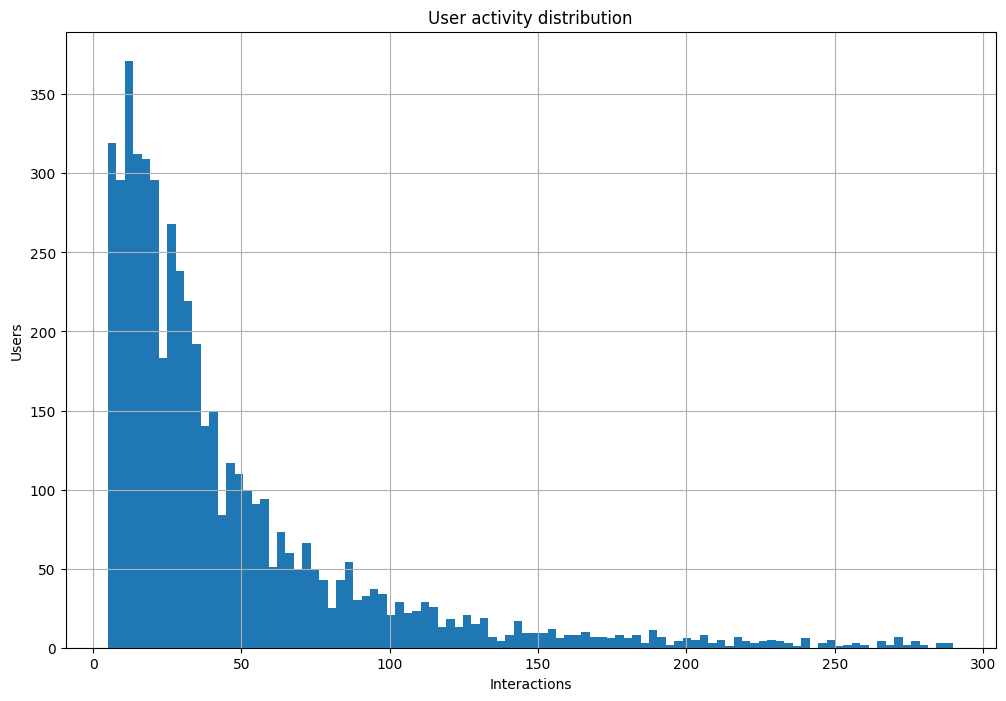

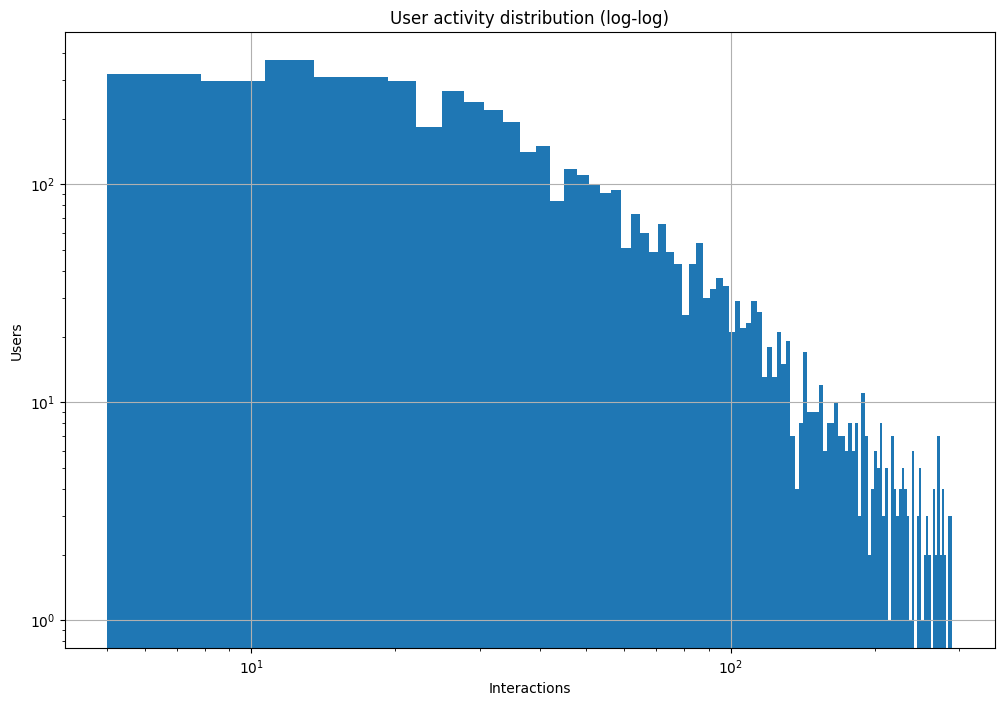

In [210]:
values = user_activity["n_interactions"].to_numpy()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.title("User activity distribution")
plt.xlabel("Interactions per user")
plt.ylabel("Users")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.xscale("log")
plt.yscale("log")
plt.title("User activity distribution (log-log)")
plt.xlabel("Interactions per user")
plt.ylabel("Users")
plt.grid(True)
plt.show()

In [225]:
item_popularity = (
    interactions
    .group_by("edition_id")
    .len(name="n_interactions")
)
item_popularity.select("n_interactions").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,n_interactions
str,f64
"""count""",74528.0
"""null_count""",0.0
"""mean""",3.102324
"""std""",8.203192
"""min""",1.0
"""50%""",1.0
"""75%""",2.0
"""90%""",6.0
"""95%""",11.0


С изданиями все не так гладко, медиана взаимодействий - 1, в среднем - 3.10, 90-ый перцентиль - 6, поэтому item2item подход выглядит менее хорошим вариантом, так как сходства между изданиями могут быть не так надежны.

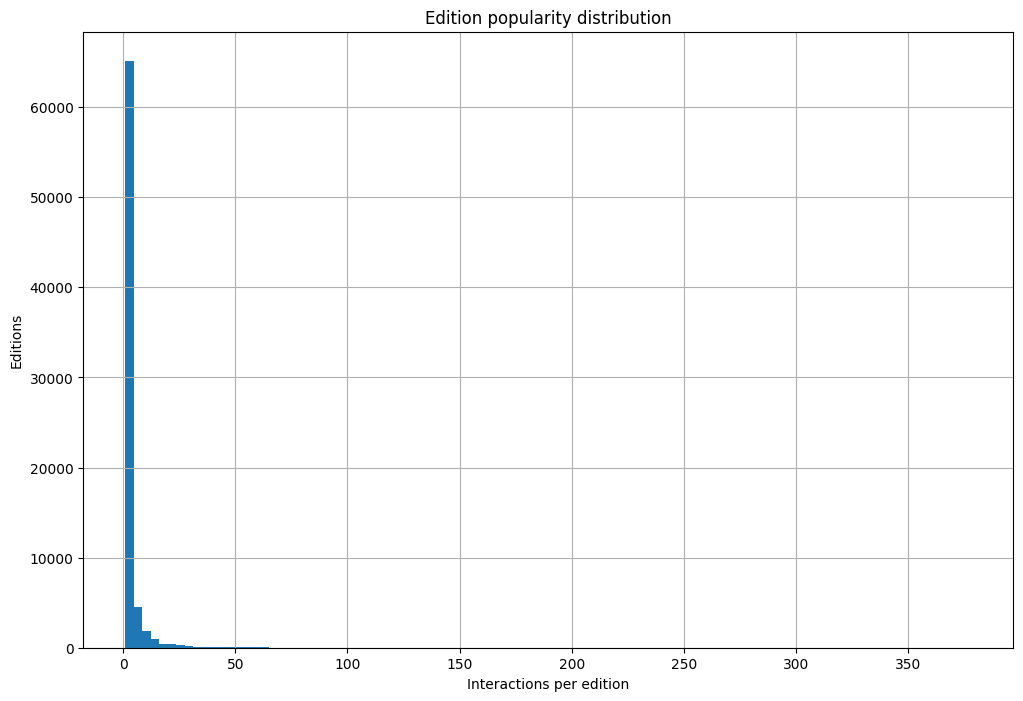

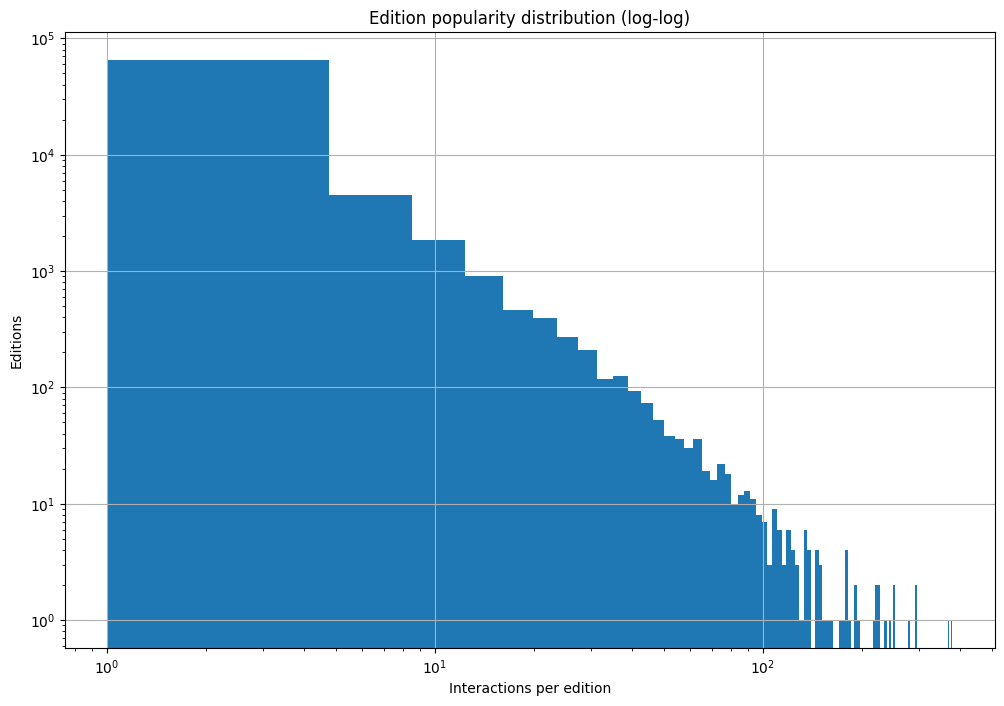

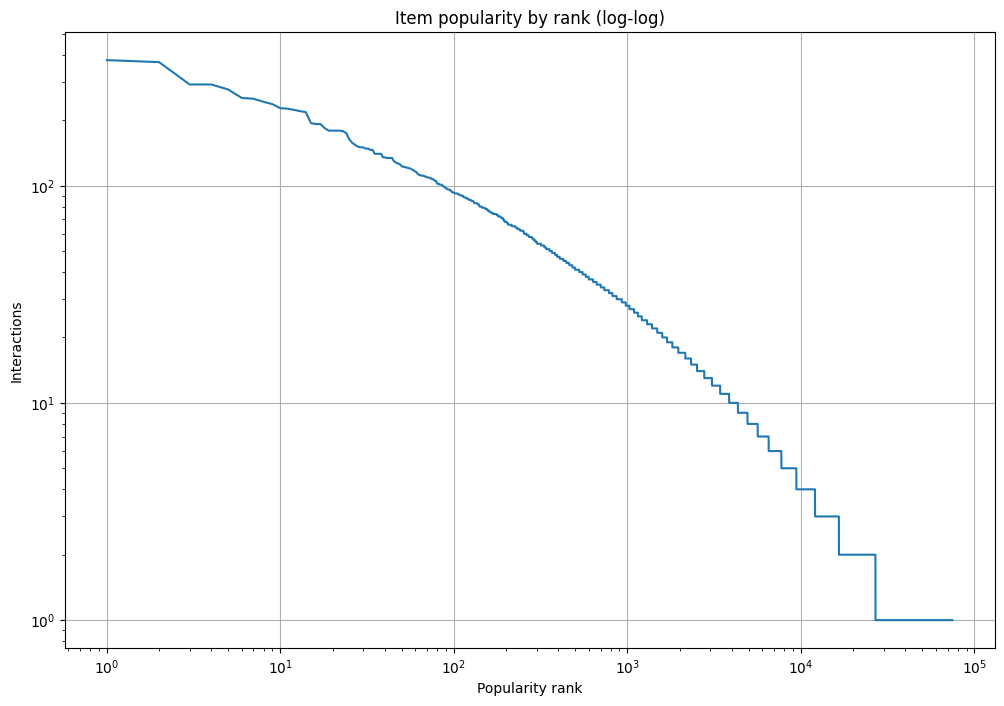

In [226]:
values = item_popularity["n_interactions"].to_numpy()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.title("Edition popularity distribution")
plt.xlabel("Interactions per edition")
plt.ylabel("Editions")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.xscale("log")
plt.yscale("log")
plt.title("Edition popularity distribution (log-log)")
plt.xlabel("Interactions per edition")
plt.ylabel("Editions")
plt.grid(True)
plt.show()

popularity = (
    item_popularity
    .sort("n_interactions", descending=True)["n_interactions"]
    .to_numpy()
)
plt.figure(figsize=(12, 8))
plt.plot(
    np.arange(1, len(popularity) + 1),
    popularity,
)
plt.xscale("log")
plt.yscale("log")
plt.title("Item popularity by rank (log-log)")
plt.xlabel("Popularity rank")
plt.ylabel("Interactions")
plt.grid(True)
plt.show()

In [234]:
# доля взаимодействий у самых популярных изданий
popularity_sorted = item_popularity.sort("n_interactions", descending=True)
total_interactions = popularity_sorted["n_interactions"].sum()
for share in [0.01, 0.05, 0.10]:
    n = max(1, int(popularity_sorted.height * share))
    interaction_share = (
        popularity_sorted["n_interactions"].head(n).sum()
        / total_interactions
    )
    print(f"Top {share:.0%} editions: {interaction_share:.2%} of all interactions")

Top 1% editions: 20.38% of all interactions
Top 5% editions: 43.19% of all interactions
Top 10% editions: 55.72% of all interactions


In [238]:
# плотность и разреженность коллаборативной матрицы
n_users = interactions["user_id"].n_unique()
n_items = interactions["edition_id"].n_unique()
n_unique_pairs = (
    interactions
    .select(
        pl.struct(["user_id", "edition_id"])
        .n_unique()
        .alias("n_unique_pairs")
    )
    .item()
)

density = n_unique_pairs / (n_users * n_items)
sparsity = 1.0 - density
pl.DataFrame({
    "metric": ["users", "items", "unique_pairs", "density", "sparsity"],
    "value": [n_users, n_items, n_unique_pairs, density, sparsity],
}, strict=False)

metric,value
str,f64
"""users""",5067.0
"""items""",74528.0
"""unique_pairs""",231038.0
"""density""",0.000612
"""sparsity""",0.999388


Матрица взаимодействий разреженная + есть явно выраженный длинный хвост распределения популярных изданий => есть резон брать most_popular как бейзлайн.

In [239]:
# добавления в список желаемого и прочтения на пользователей
event_activity = (
    interactions
    .group_by(["user_id", "event_type"])
    .len(name="n_events")
    .pivot(
        on="event_type",
        index="user_id",
        values="n_events",
        aggregate_function="first",
    )
    .fill_null(0)
    .rename({
        "1": "wishlist",
        "2": "read",
    })
)
event_activity.select(["wishlist", "read"]).describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,wishlist,read
str,f64,f64
"""count""",5067.0,5067.0
"""null_count""",0.0,0.0
"""mean""",16.6866,28.943951
"""std""",31.174801,29.297345
"""min""",0.0,0.0
"""50%""",4.0,21.0
"""75%""",18.0,35.0
"""90%""",50.0,60.0
"""95%""",77.0,84.0
